## 1. Algoritmo $K-$Means:
1. Para empezar el algoritmo, asignas aleatoriamente a cada observación un número entre 1 y $K$, donde $K$ es el número total de clústeres que quieres formar. Esto significa que cada observación se pone inicialmente en uno de los $K$ grupos, aunque esta asignación sea totalmente arbitraria.

2. Iterar hasta que las asignaciones de clúster no cambien:

  a) Calcula el centroide, que es simplemente el vector promedio de todas las observaciones del clúster, componente a componente. Por ejemplo, si los datos tienen $p$ características y el clúster $k$ tiene $i$ observaciones, calculas la media de cada característica sobre esas $i$ observaciones para obtener el centroide:
  $$\mu_k = \left(\frac{1}{|C_k|} \sum_{i \in C_k} x_{i1}, \quad\frac{1}{|C_k|}\sum_{i \in C_k} x_{i2}, \quad\dots, \quad\frac{1}{|C_k|} \sum_{i \in C_k} x_{ip}\right)$$

  b) Reasignar observaciones al clúster más cercano. Para cada observación $x_i$, calculas la distancia euclidiana a cada uno de los centroides $\mu_1, \mu_2, \dots, \mu_K$.

  La distancia euclidiana entre un punto $x_i$ y un centroide $\mu_k$ se define como:
  $$d(x_i, \mu_k) = \sqrt{\sum_{j=1}^p (x_{ij} - \mu_{kj})^2}$$

  Luego, asignas la observación $x_i$ al clúster cuyo centroide esté más cercano, es decir, aquel que minimice la distancia $d(x_i, \mu_k)$.

K-medias agrupa los datos asignando cada punto al centroide más cercano y luego recalculando esos centroides como el promedio de los puntos en cada grupo. Cada vez que se repite este proceso, la agrupación mejora o se mantiene igual, porque las medias minimizan la distancia dentro de los grupos. El algoritmo se detiene cuando ya no hay cambios, alcanzando un óptimo local. Como el resultado depende del punto de partida, se recomienda repetirlo varias veces para encontrar una mejor solución.

##2. Algoritmo del Agrupamiento Jerárquico

Comenzamos definiendo una medida de disimilitud entre cada par de observaciones. Generalmente, se utiliza la distancia euclidiana en datos numéricos, pero se pueden utilizar otras como la Distancia de Manhattan (suma las diferencias absolutas entre las coordenadas.), Distancia de Mahalanobis, entre otras.

Partiendo en la base del dendograma, cada una de las $n$ observaciones es tratada como su propio clúster. Los dos clústers más similares se fusionan, de modo que ahora hay $n-1$ grupos. A continuación, los dos clústers más similares se fusionan de nuevo, de modo que ahora hay $n-2$. El algoritmo continúa de esta manera, de manera iterativa, hasta que todas las observaciones pertenecen a un solo clúster y el dendrograma está completo.

1. Comience con $n$ observaciones y una medida (como la distancia euclidiana) de todas las $\binom{n}{2} = \frac{n(n - 1)}{2}$ disimilitudes por pares. Trate cada observación como su propio clúster.
2. Para $i = n, n−1,...,2$:

  (a) Examine todas las disimilitudes intergrupos por pares entre los i clústers e identifique el par de estos menos disímiles (es decir, más similares). Fusione estos dos clústers. La disimilitud entre estos dos indica la altura en el dendrograma en la que debe colocarse la fusión.
  
  (b) Calcule las nuevas disimilitudes interclústers por pares entre los $i-1$ grupos restantes.

Esto nos da un concepto de disimilitud entre pares de observaciones, pero ¿cómo definimos la disimilitud entre dos clústers si uno o ambos contienen múltiples observaciones? Esta extensión se logra desarrollando el concepto de enlace, que define la disimilitud entre dos grupos de observaciones. Los cuatro tipos de enlaces más comunes (completo, promedio, simple y centroide), utilizados en el paso 2(b), se detallan a continuación:

  (a) **Completo**: Calcule todas las disimilitudes por pares entre las observaciones del clúster A y del clúster B, y registre la mayor de estas disimilitudes.

  (b) **Simple**: Disimilitud mínima entre clústeres. La disimilitud entre A y B es igual a la menor distancia entre cualquier punto de A y cualquier punto de B.Esto solo considera un par de puntos: el par más cercano entre los dos clústeres. No importa lo que pase con el resto de los puntos. El enlace simple puede resultar en clústeres extensos y rezagados, en los que las observaciones individuales se fusionan una a una.
  Para observar esto último suponga que tiene

      b) A ........ B
  Si hay una cadena de puntos cercanos entre dos regiones, el algoritmo puede unirlas prematuramente, aunque los extremos `A` y `B` estén muy lejos y sean muy distintos, el algoritmo los conecta por la serie de enlaces mínimos.

  (c) **Promedio**: Disimilitud media entre conglomerados. Calcule todas las disimilitudes por pares entre las observaciones del clúster A y las del clúster B, y registre el promedio de estas disimilitudes.

  (d) **Centroide**: Para cada clúster (A y B), calculas su centroide, que es el promedio de las coordenadas de sus observaciones. La vinculación del centroide puede dar lugar a inversiones indeseables: El grupo A se une con B a una altura (disimilitud) de 5. Luego ese nuevo grupo (A+B) se une con C a una disimilitud de 3. ¡Eso no tiene sentido lógico en un dendrograma! Porque los grupos deben unirse a alturas cada vez mayores o iguales, nunca más bajas.


### Importancia del escalamiento

A veces, unas variables tienen mucha más variación que otras (por ejemplo: se compran más calcetines que computadores).

Si no escalas: las variables con mayor escala o mayor varianza (como calcetines) dominarán la medida de disimilitud, por lo que es necesario hacer un escalamiento estándar para asignarle a cada variable la misma importancia de agrupación jerárquica.







### Laboratorio Clustering: 👥 Mall Customer Segmentation Data

En esta sección trabajarás con el dataset `Mall Customer Segmentation Data`, el cual contiene información sobre $200$ clientes de un centro comercial, incluyendo su edad, género, ingreso anual estimado y un puntaje de gasto asignado por el mall, que refleja cuánto y con qué frecuencia compran. Este dataset es especialmente útil para aplicar métodos de agrupamiento como K-Means y clustering jerárquico, ya que permite identificar patrones de comportamiento entre clientes, tales como grupos con alto ingreso pero bajo gasto, o jóvenes con alto poder adquisitivo.
Este dataset está compuesto por $5$ variables:
* `CustomerID`: Es una variable entera, que contiene el ID único del cliente.
* `Gender`: Variable categórica	que indica el Género del cliente: Male o Female.
* `Age`: variable	numérica que contiende la edad del cliente.
* `Annual Income (k$)`: variable numérica. Indica el ingreso anual estimado en miles de dólares.
* `Spending Score (1-100)`: variable numérica	que señala la puntuación (asignada por el centro comercial) del comportamiento de gasto del cliente. Su valor va de 1 (mínimo gasto) a 100 (máximo gasto).

Para cargar los datos, las librerías y hacer un análisis exploratorio, corra las siguientes dos celdas de código.

In [1]:
import os
from google.colab import drive
drive.mount('/content/drive')

os.chdir('/content/drive/MyDrive/Exam_ML')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

mall = pd.read_csv('Mall_Customers.csv')
mall.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
mall.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Ahora deberá implementar el algoritmo $K$-Means anteriormente presentado. Para ello deberá formar una matriz `X` que contrendrá las columnas `Age`, `Annual Income (k$)` y `Spending Score (1-100)`, y proceder como se explica a continuación:

* Estandarizar los datos. Puede utilizar `StandarScaler` de `sklearn.preprocessing`.

* Deberá definir la función `centroide` que reciba los parámetros `K`, el cual es el número de clúster que quieres formar, `data` y `label`, que corresponden a la asignación arbitraria inicial de cada observación a un clúster. Esta función deberá retornar el centroide $\mu_k$. Puede serle útil definir $\mu_k$ como un diccionario que contenga como claves los clúster y, la colección de elementos asociados a esa llave, el vector centroide.

* Definir la función `asignar_cluster` que reciba `K`, `data`, `mu_k` y que tiene por función asignar cada observación $x_i$ al cluster, cuya distancia entre $x_i$ y el centroide correspondiente, sea mínima.

* Por último, deberá aplicar las dos funciones previamente definidas, hasta que las etiquetas no cambien o se cumpla un número máximo de cien iteraciones (`max_iter = 100`).

In [6]:
X = mall[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Como las tres columnas aportan datos que tienen escalas completamente distintas entre sí, estandarice los datos
# Puede usar la función StandardScaler de sklearn

scaler = StandardScaler()
X = scaler.fit_transform(X)

# Asignar aleatoriamente a cada observación x_i un número entre 1 y  K mediante etiquetas

K = 4

labels = np.random.randint(1, K + 1, size=len(X))

# Definir la función que retorna los centroides de cada cluster

def centroide(K, data, label):
  mu_k = {}
  for i in range(1, K + 1):
    mu_k[i] = np.mean(data[label == i], axis=0)
  return mu_k

# Definir la función que asigna cada observación x_i al clúster cuya distancia euclidiana entre la observación y el centroide es menor

def asignar_cluster(K, data, mu_k):
  label = np.zeros(len(data))
  for i in range(len(data)):
    distancias = np.zeros(K)
    for j in range(1, K + 1):
      distancias[j - 1] = np.linalg.norm(data[i] - mu_k[j])
    label[i] = np.argmin(distancias) + 1
  return label

# Aplique el algoritmo una max_iter cantidad de iteraciones

max_iter = 100

for i in range(max_iter):
  mu_k = centroide(K, X, labels)
  labels_prev = asignar_cluster(K, X, mu_k)


In [10]:
X = mall[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Como las tres columnas aportan datos que tienen escalas completamente distintas entre sí, estandarice los datos
# Puede usar la función StandardScaler de sklearn

scaler = StandardScaler()
X = scaler.fit_transform(X)

# Asignar aleatoriamente a cada observación x_i un número entre 1 y  K mediante etiquetas

K = 3

labels = np.random.randint(1, K + 1, size=len(X))

# Definir la función que retorna los centroides de cada cluster

def centroide(K, data, label):
  mu_k = {}
  for i in range(1, K + 1):
    mu_k[i] = np.mean(data[label == i], axis=0)
  return mu_k

# Definir la función que asigna cada observación x_i al clúster cuya distancia euclidiana entre la observación y el centroide es menor

def asignar_cluster(K, data, mu_k):
  label = np.zeros(len(data))
  for i in range(len(data)):
    distancias = np.zeros(K)
    for j in range(1, K + 1):
      distancias[j - 1] = np.linalg.norm(data[i] - mu_k[j])
    label[i] = np.argmin(distancias) + 1
  return label

# Aplique el algoritmo una max_iter cantidad de iteraciones

max_iter = 100

for i in range(max_iter):
  mu_k = centroide(K, X, labels)
  labels = asignar_cluster(K, X, mu_k)

#### Ahora implemente PCA para poder visualizar los datos en 2D, tal como hicieron en la actividad evaluada 1.

Como los datos ya se encuentran estandarizados, usted deberá:
* Calcular la matriz de covarianza $C$.
* Encontrar los autovalores y autovectores de $C$.
* Calcular la matriz de $W$ de autovectores ordenados de forma descendente y tomar sólo las dos primeras componentes principales.
* Obtener la matriz $T$ de los datos proyectados a la nueva base.


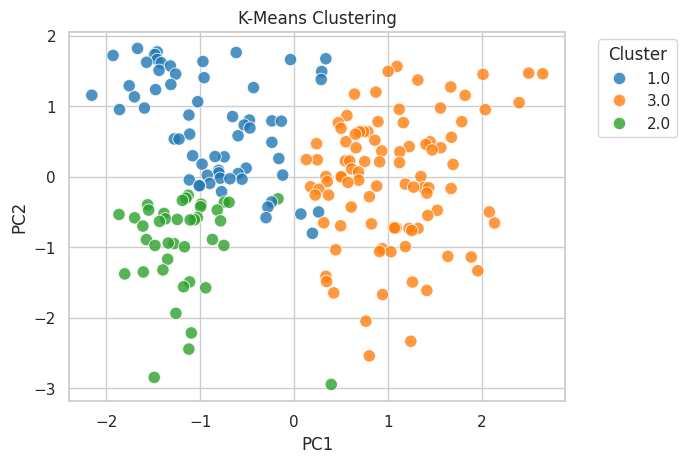

In [11]:
# Visualice utilizando PCA

# Matriz Covarianza

C = np.cov(X.T)
# Calcule los autovalores y autovectores de C

autovalores, autovectores = np.linalg.eig(C)

idx_desc = np.argsort(autovalores)[::-1]
autovalores_desc = autovalores[idx_desc]
W = autovectores[:, idx_desc]
W_reducido = W[:, :2]# En esta parte tomaremos sólo las dos primeras componentes principales

# Obtenga T como la nueva matriz de datos proyectados en la base W
T = np.dot(X, W_reducido)

# Gráfico

df_plot = pd.DataFrame({'PC1': T[:, 0], 'PC2': T[:, 1], 'Cluster': labels.astype(str)})
sns.set(style='whitegrid', context='notebook')
sns.scatterplot(data=df_plot, x='PC1', y='PC2', hue='Cluster', palette='tab10', s=80, alpha=0.8)
plt.title('K-Means Clustering')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

Sin embargo y, luego de haber hecho todo esto, nada nos asegura que el valor de $K$ definido previamente por usted, es un valor óptimo para la separación de los datos.

### Para encontrar el valor óptimo de clústers $K$ haga un gráfico. Para ello usted deberá proceder de la siguiente forma:

* Defina una función llamada `inercia` que reciba como parámetros el vector centroide `mu_k`, la `data` y las etiquetas `label`. En ella deberás calcular la inercia o también llamada Sum of Squared Errors (SSE), la cual se define como
$$\text{inercia} =  \sum_{k=1}^K \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$$

* Ahora, para cada valor de K (por ejemplo, de 1 a 10), ejecutas K-Means, calculando, además, la inercia asociada a cada uno de ellos, aplicando la función previamente definida.

* Grafique $K$ vs inercia.

El valor óptimo de $K$ corresponde al punto donde la inercia intra-cluster presenta una disminución abrupta seguida de una estabilización, formando una especie de 'codo' en la curva. Comente en la celda de texto disponible para este propósito cuál parece ser el valor de $K$ que mejor representa este comportamiento y justifique su elección en base a la forma de la curva.

/usr/local/lib/python3.11/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.11/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.11/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.11/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.11/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.11/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.11/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWa

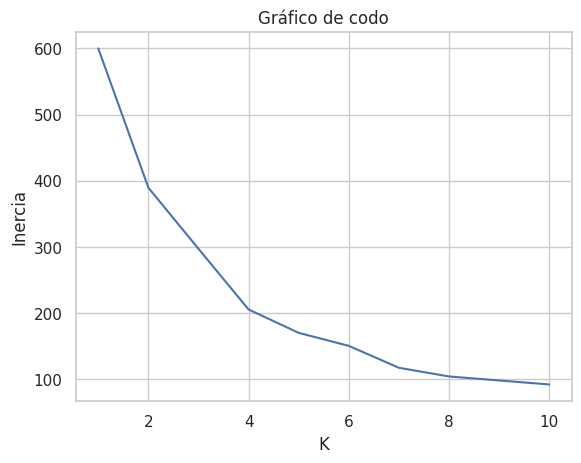

In [13]:
def inercia(mu_k, data, label, K):
  sse = 0
  for k in range(1, K + 1):
    sse += np.sum(np.linalg.norm(data[label == k] - mu_k[k])**2)
  return sse

inercias = []
max_iter = 100
K_max = 20

for k in range(1, K_max + 1):
  labels = np.random.randint(1, k + 1, size=X.shape[0])
  labels_prev = np.copy(labels)
  for i in range(max_iter):
    mu_k = centroide(k, X, labels)
    labels = asignar_cluster(k, X, mu_k)
    if np.array_equal(labels_prev, labels):
      break
  inercias.append(inercia(mu_k, X, labels, k))

sns.lineplot(x = range(1, K_max + 1), y = inercias)
plt.title('Gráfico de codo')
plt.xlabel('K')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()


✍️ Respuesta:

El K óptimo es entre el 2 y el 6, elegiría el 4 ya que el donde se ejerció la mayor inflexión o sea una mayor pendiente antes de empezar a estabilizarse.

Ahora deberá implementar el algoritmo de clustering jerárquico aglomerativo, utilizando el criterio de distancia mínima entre pares de observaciones (enlace simple o single linkage). Para ello, deberá trabajar con una matriz `X` que contenga las mismas columnas que en el caso anterior, y proceder como se indica a continuación:

* Estandarice los datos.

* Defina la función `distancia_euclidiana` que reciba dos vectores `a` y `b`, y retorne su distancia euclidiana. Puede utilizar `np.linalg.norm()` para este cálculo.

* Defina la función `matriz_distancias(X)`, que calcule la matriz de distancias simétrica entre todas las observaciones de `X`, utilizando la función anterior. La entrada es la matriz `X` (estandarizada), y la salida debe ser una matriz `D` de tamaño $n \times n$, donde $n$ es el número de observaciones.

* A continuación, defina la función `asignar_cluster(X)`, que implemente el algoritmo aglomerativo. Esta función debe seguir los siguientes pasos:

  - Inicializar cada observación como un clúster separado. Puede representarlos con un diccionario cluster de la forma `{0: [0], 1: [1], ..., n-1: [n-1]}`.

  - Iterativamente, buscar el par de clústers $(C_a, C_b)$ más cercanos, de acuerdo a la distancia mínima entre cualquiera de sus elementos (criterio de enlace simple).

  - Fusionar dichos clústers en uno nuevo, asignándole un nuevo identificador entero creciente.

  - Guardar en una lista `historial = []` los pasos del agrupamiento, registrando una tupla con la forma `(índice_cluster_a, índice_cluster_b, distancia_entre_clusters, número_de_elementos_en_cluster_fusionado)` en cada iteración.

  - Repetir el procedimiento hasta que todas las observaciones hayan sido agrupadas en un único clúster.

  - Finalmente, la función `asignar_cluster(X)` debe retornar el historial completo del proceso de fusión de clústers, útil para construir posteriormente un dendrograma.



In [19]:
X = mall[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].values

# Estandarizar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

def distancia_euclidiana(a, b):
  d = np.linalg.norm(a - b)
  return d

""" Una matriz distancia debería ser simétrica ((i,j) = (j,i)) y las distancia entre los mismos puntos (i=i) deben ser 0 """
def matriz_distancias(X):
  n = X.shape[0]
  D = np.full((n, n), np.inf)
  np.fill_diagonal(D, 0)
  for i in range(n):
    for j in range(i + 1, n):
      D[i, j] = distancia_euclidiana(X[i], X[j])
      D[j, i] = D[i, j]
  return D

def asignar_cluster(X):
  D = matriz_distancias(X)
  cluster = {}
  for i in range(len(X)):
    cluster[i] = [i]


  llaves = list(cluster.keys()) # Convierte en lista las llaves del diccionario, para recorrer sin problemas [0, 1, ..., n]
  id = len(X)
  historial = []

  while len(cluster) > 1: # Hacemos el loop hasta que ya no queden clusters aislados
    min_dist = np.inf
    a,b = -1,-1
    for i in llaves:
      for j in llaves:
        if i < j:
          dist = min(distancia_euclidiana(X[l],X[m]) for l in cluster[i] for m in cluster[j])
          if dist < min_dist:
            min_dist = dist
            a,b = i,j
    cluster[id] = cluster[a] + cluster[b]
    historial.append((a,b,min_dist, len(cluster[id])))
    id += 1
    del cluster[a]
    del cluster[b]
    llaves = list(cluster.keys())

  return historial

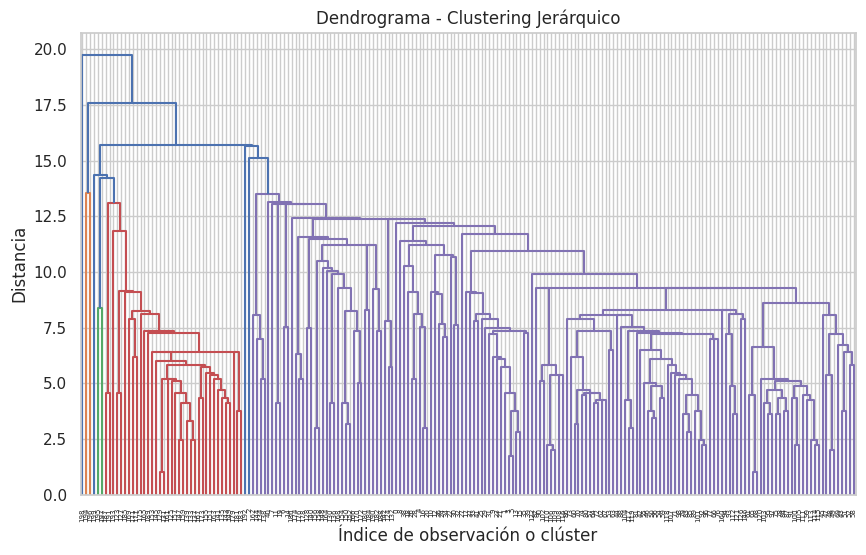

In [20]:
# Graficamos el dendograma resultante
from scipy.cluster.hierarchy import dendrogram

linkage_matrix = np.array(asignar_cluster(X))
plt.figure(figsize=(10, 6))
dendrogram(linkage_matrix)
plt.title("Dendrograma - Clustering Jerárquico")
plt.xlabel("Índice de observación o clúster")
plt.ylabel("Distancia")
plt.grid(True)
plt.show()